# Exercitiul 3: Restaurarea unei imagini binare cu un MRF

### c) Explicatia energiei si a potentialelor
Energia totala $E(x; y) = \lambda \sum_i (x_i - y_i)^2 + \sum_{(i,j) \in E} (x_i - x_j)^2$ echilibreaza doua interese contradictorii:
* **Primul termen (fidelitatea):** Penalizeaza diferentele dintre pixelul reconstruit ($x_i$) si pixelul original murdar ($y_i$).
* **Al doilea termen (netezirea):** Penalizeaza diferentele dintre vecini. Vrem ca imaginea sa aiba forme continue.

### d) Algoritmul ICM (Iterated Conditional Modes)
Deoarece pentru o grila 5x5 (care contine cicluri) inferenta exacta este extrem de costisitoare, am ales metoda aproximativa recomandata: **ICM**. 
Algoritmul porneste initial cu imaginea observata (murdara). La fiecare pas, analizeaza fiecare pixel in parte si ii alege starea (0 sau 1) care minimizeaza energia locala, tinand cont doar de valoarea sa initiala si de vecinii sai actuali. Procesul se repeta pana cand imaginea nu se mai schimba deloc. Desi garanteaza doar gasirea unui minim local de energie (nu obligatoriu MAP-ul global), este un algoritm extrem de rapid si stabil.

### e) Efectul parametrului $\lambda$
* **$\lambda$ mic (ex. 0.3):** Reteaua prioritizeaza puternic netezirea. Rezultatul va fi mai sters, rotunjind prea mult formele si eliminand detalii din patratul original.
* **$\lambda$ mare (ex. 3.0):** Reteaua este obligata sa ramana fidela observatiei initiale, ignorand netezirea. Astfel, va pastra o mare parte din zgomotul (punctele gresite) din poza.

Rulam algoritmul ICM...


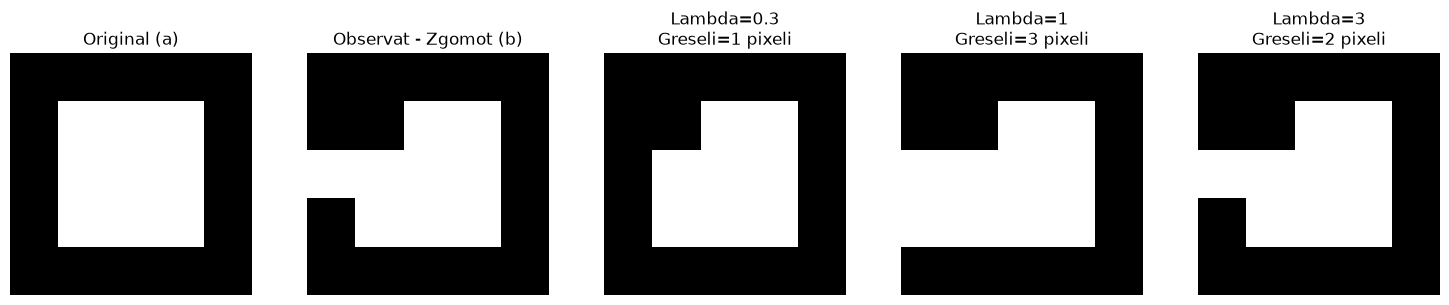

Gata!


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# a) Imagine originala (patrat alb in centru pe fond negru)
img = np.zeros((5, 5), dtype=int)
img[1:4, 1:4] = 1

# b) Adaugam zgomot 10%
np.random.seed(42)
y = img.copy()
masca_zgomot = np.random.rand(5, 5) < 0.1
y[masca_zgomot] = 1 - y[masca_zgomot]

# d) Implementarea algoritmului aproximativ ICM (Iterated Conditional Modes)
def restaureaza_imagine_icm(y, lmbd):
    x = y.copy() # Initializam restaurarea fix cu imaginea observata
    schimbat = True
    
    while schimbat:
        schimbat = False
        for i in range(5):
            for j in range(5):
                val_curenta = x[i, j]
                
                # Extragem vecinii valizi (fara sa iesim din matrice)
                vecini = []
                if i > 0: vecini.append(x[i-1, j]) # vecin Sus
                if i < 4: vecini.append(x[i+1, j]) # vecin Jos
                if j > 0: vecini.append(x[i, j-1]) # vecin Stanga
                if j < 4: vecini.append(x[i, j+1]) # vecin Dreapta
                
                # E(0): Energia locala daca pixelul ar fi 0 (negru)
                e0 = lmbd * (0 - y[i, j])**2 + sum((0 - v)**2 for v in vecini)
                
                # E(1): Energia locala daca pixelul ar fi 1 (alb)
                e1 = lmbd * (1 - y[i, j])**2 + sum((1 - v)**2 for v in vecini)
                
                # Alegem pixelul cu energia minima (MAP local)
                noua_val = 0 if e0 < e1 else 1
                
                # Daca starea optima e diferita de cea curenta, o actualizam
                if noua_val != val_curenta:
                    x[i, j] = noua_val
                    schimbat = True
                    
    return x

print("Rulam algoritmul ICM...")

# e) Rulam pentru lambda 0.3, 1 si 3 si generam rezultatele vizuale
lambdas = [0.3, 1, 3]
fig, axes = plt.subplots(1, len(lambdas) + 2, figsize=(15, 3))

axes[0].imshow(img, cmap='gray'); axes[0].set_title('Original (a)')
axes[1].imshow(y, cmap='gray'); axes[1].set_title('Observat - Zgomot (b)')

for idx, l in enumerate(lambdas):
    reconstructie = restaureaza_imagine_icm(y, lmbd=l)
    greseli = np.sum(reconstructie != img)
    axes[idx+2].imshow(reconstructie, cmap='gray', vmin=0, vmax=1)
    axes[idx+2].set_title(f'Lambda={l}\nGreseli={greseli} pixeli')

for ax in axes: 
    ax.axis('off')
    
plt.tight_layout()
plt.show()
print("Gata!")